--- [STEP 1 & 2] Loading Data and Performing EDA ---
Dataset Shape after cleaning: (110, 9)
Missing Values:
age                     0
screen_width            0
screen_height           0
total_taps              0
successful_taps         0
miss_taps               0
tap_accuracy            0
avg_reaction_time_ms    0
button_label            0
dtype: int64
Target Distribution:
button_label
2    0.400000
1    0.290909
0    0.209091
3    0.100000
Name: proportion, dtype: float64


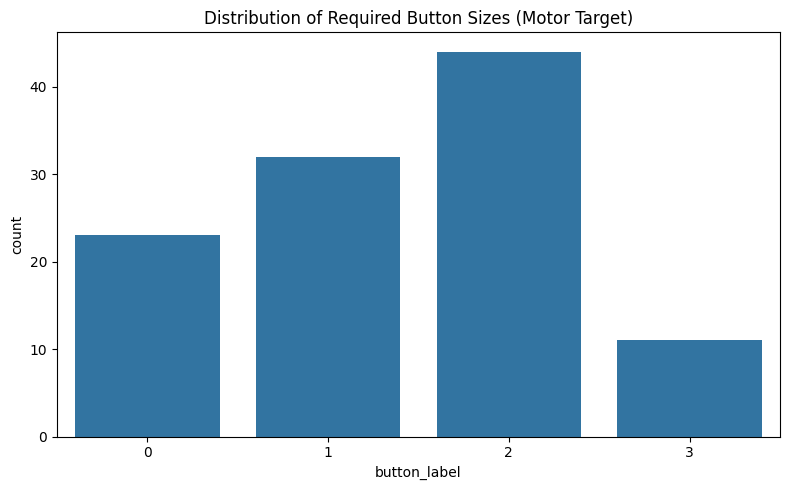


--- [STEP 3] Preprocessing ---
Preprocessing Complete. Features extracted: ['age', 'screen_width', 'screen_height', 'total_taps', 'successful_taps', 'miss_taps', 'tap_accuracy', 'avg_reaction_time_ms']

--- [STEP 4] Train/Test Split ---
Training set: (88, 8), Test set: (22, 8)

--- [STEP 5, 7, 8] Training and Evaluation ---
Training Decision Tree...
Training Random Forest...
Training XGBoost Base...
Training MLP Classifier...

--- [STEP 6] Hyperparameter Tuning for XGBoost ---
Best Parameters: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}

--- [STEP 9] Model Comparison ---
            Model  CV_Accuracy    CV_Std  Test_Accuracy  Balanced_Accuracy  \
0   Decision Tree     0.966013  0.044789       1.000000           1.000000   
2    XGBoost Base     1.000000  0.000000       1.000000           1.000000   
4   XGBoost Tuned     1.000000  0.000000       1.000000           1.000000   
1   Random Forest     0.932680  0.041420       0.954545           0.875000

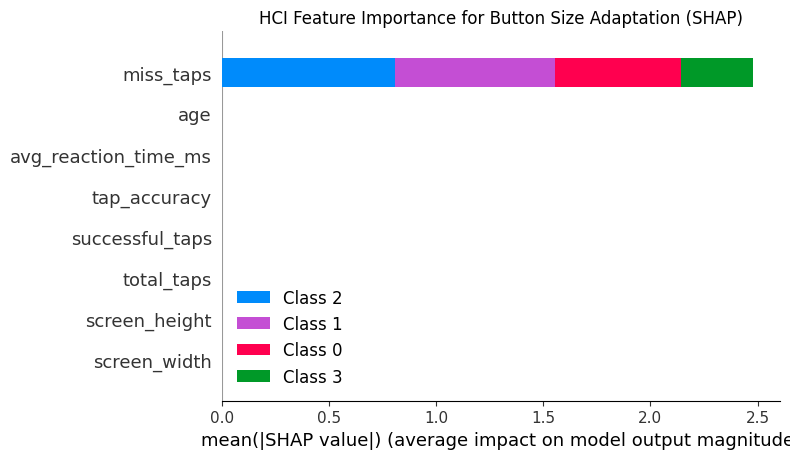


--- [STEP 12 & 13] Saving Models and Pipeline ---
Artifacts saved successfully.

--- [PREDICTION] Recommending Button Size for App Interface ---
Input Metrics: {'age': 23, 'screen_width': 1080, 'screen_height': 2400, 'total_taps': 20, 'successful_taps': 15, 'miss_taps': 5, 'tap_accuracy': 0.75, 'avg_reaction_time_ms': 380, 'miss_rate': 0.25}
👉 Recommended Button Size for App: 0


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
from datetime import datetime

# ML & Scikit-Learn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, matthews_corrcoef, cohen_kappa_score,
                             confusion_matrix, classification_report, log_loss)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

# Explainability
import shap

warnings.filterwarnings('ignore')

class AUI_ButtonSize_Pipeline:
    def __init__(self, csv_path=None):
        self.csv_path = csv_path  
        self.df = None
        self.target_col = 'button_label'
        self.models = {}
        self.results = {}
        self.best_model = None
        
        # Artifacts
        self.label_encoder = LabelEncoder()
        self.scaler = StandardScaler()
        self.features = []

    # ==========================================
    # STEP 1 & 2: Load Data and EDA
    # ==========================================
    def load_and_eda(self):
        """Loads dataset and performs comprehensive Exploratory Data Analysis."""
        print("--- [STEP 1 & 2] Loading Data and Performing EDA ---")
        if self.csv_path:
            raw_df = pd.read_csv(self.csv_path)  
        else:
            print("[INFO] No CSV provided.")
            return

        # Domain/Dataset Cleaning for AUI framework
        df_clean = raw_df.copy()
        
        # Remove inactive sessions if total_taps exists and is 0
        if 'total_taps' in df_clean.columns:
            df_clean = df_clean[df_clean['total_taps'] > 0]
            
        # Remove invalid ages if age exists
        if 'age' in df_clean.columns:
            df_clean = df_clean[df_clean['age'] <= 100]

        # Drop identifiers and experimental stage columns (not present in live app)
        drop_cols = ['user_id', 'session_id', 'stage', 'IFI']
        for col in drop_cols:
            if col in df_clean.columns:
                df_clean = df_clean.drop(col, axis=1)

        self.df = df_clean

        # EDA execution
        print(f"Dataset Shape after cleaning: {self.df.shape}")
        print(f"Missing Values:\n{self.df.isnull().sum()}")
        print(f"Target Distribution:\n{self.df[self.target_col].value_counts(normalize=True)}")
        
        # Plotting distributions (HCI behavior focus)
        plt.figure(figsize=(8, 5))
        sns.countplot(x=self.target_col, data=self.df)
        plt.title("Distribution of Required Button Sizes (Motor Target)")
        plt.tight_layout()
        plt.show()

    # ==========================================
    # STEP 3: Preprocessing
    # ==========================================
    def preprocess_data(self):
        """Handles missing values, encodes targets, and scales HCI features."""
        print("\n--- [STEP 3] Preprocessing ---")
        if self.df is None: return None, None
        
        df_clean = self.df.copy()
        numeric_cols = df_clean.select_dtypes(include=[np.number]).columns
        df_clean[numeric_cols] = df_clean[numeric_cols].fillna(df_clean[numeric_cols].median())

        y = self.label_encoder.fit_transform(df_clean[self.target_col])
        X = df_clean.drop(self.target_col, axis=1)
        self.features = X.columns.tolist()

        X_scaled = pd.DataFrame(self.scaler.fit_transform(X), columns=self.features)
        
        print("Preprocessing Complete. Features extracted:", self.features)
        return X_scaled, y

    # ==========================================
    # STEP 4: Train/Test Split
    # ==========================================
    def split_data(self, X, y):
        print("\n--- [STEP 4] Train/Test Split ---")
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.20, stratify=y, random_state=42
        )
        print(f"Training set: {X_train.shape}, Test set: {X_test.shape}")
        return X_train, X_test, y_train, y_test

    # ==========================================
    # STEP 5 & 7 & 8: Train, Cross-Validate, Evaluate
    # ==========================================
    def evaluate_model(self, model, X_train, y_train, X_test, y_test, model_name):
        skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        cv_scores = []
        
        X_tr_arr = X_train.values if isinstance(X_train, pd.DataFrame) else X_train
        y_tr_arr = y_train.values if isinstance(y_train, pd.Series) else y_train
        
        for train_idx, val_idx in skf.split(X_tr_arr, y_tr_arr):
            clone_model = type(model)(**model.get_params())
            clone_model.fit(X_tr_arr[train_idx], y_tr_arr[train_idx])
            cv_scores.append(clone_model.score(X_tr_arr[val_idx], y_tr_arr[val_idx]))
        
        import time
        start_time = time.time()
        model.fit(X_train, y_train)
        train_time = time.time() - start_time
        
        start_time = time.time()
        y_pred = model.predict(X_test)
        pred_time = time.time() - start_time

        acc = accuracy_score(y_test, y_pred)
        bal_acc = balanced_accuracy_score(y_test, y_pred)
        mcc = matthews_corrcoef(y_test, y_pred)
        kappa = cohen_kappa_score(y_test, y_pred)
        
        metrics = {
            "Model": model_name,
            "CV_Accuracy": np.mean(cv_scores),
            "CV_Std": np.std(cv_scores),
            "Test_Accuracy": acc,
            "Balanced_Accuracy": bal_acc,
            "F1_Weighted": f1_score(y_test, y_pred, average='weighted'),
            "Precision": precision_score(y_test, y_pred, average='weighted'),
            "Recall": recall_score(y_test, y_pred, average='weighted'),
            "MCC": mcc,
            "Cohen_Kappa": kappa,
            "Train_Time(s)": train_time,
            "Pred_Time(s)": pred_time
        }
        
        self.results[model_name] = metrics
        return model, y_pred

    def train_all_models(self, X_train, y_train, X_test, y_test):
        print("\n--- [STEP 5, 7, 8] Training and Evaluation ---")
        
        models_to_train = {
            "Decision Tree": DecisionTreeClassifier(random_state=42),
            "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
            "XGBoost Base": XGBClassifier(eval_metric='mlogloss', random_state=42),
            "MLP Classifier": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, random_state=42)
        }

        for name, clf in models_to_train.items():
            print(f"Training {name}...")
            trained_model, _ = self.evaluate_model(clf, X_train, y_train, X_test, y_test, name)
            self.models[name] = trained_model

    # ==========================================
    # STEP 6: XGBoost Hyperparameter Tuning
    # ==========================================
    def tune_xgboost(self, X_train, y_train):
        print("\n--- [STEP 6] Hyperparameter Tuning for XGBoost ---")
        xgb_clf = XGBClassifier(eval_metric='mlogloss', random_state=42)
        
        param_grid = {
            'max_depth': [3, 5, 7],
            'learning_rate': [0.01, 0.1, 0.2],
            'n_estimators': [100, 200],
            'subsample': [0.8, 1.0]
        }
        
        grid_search = GridSearchCV(estimator=xgb_clf, param_grid=param_grid, 
                                   cv=StratifiedKFold(n_splits=3), scoring='f1_weighted', n_jobs=-1)
        grid_search.fit(X_train, y_train)
        
        print(f"Best Parameters: {grid_search.best_params_}")
        best_xgb = grid_search.best_estimator_
        self.models['XGBoost Tuned'] = best_xgb
        self.best_model = best_xgb
        return best_xgb

    # ==========================================
    # STEP 9: Model Comparison
    # ==========================================
    def compare_models(self):
        print("\n--- [STEP 9] Model Comparison ---")
        df_results = pd.DataFrame(self.results.values())
        print(df_results.sort_values(by="F1_Weighted", ascending=False))
        df_results.to_csv("aui_model_comparison_results.csv", index=False)
        return df_results

    # ==========================================
    # STEP 10: Explainability (SHAP for AUI)
    # ==========================================
    def explain_model(self, X_train):
        print("\n--- [STEP 10] SHAP Explainability ---")
        explainer = shap.TreeExplainer(self.best_model)
        shap_values = explainer.shap_values(X_train)
        
        plt.figure(figsize=(10, 6))
        shap.summary_plot(shap_values, X_train, plot_type="bar", show=False)
        plt.title("HCI Feature Importance for Button Size Adaptation (SHAP)")
        plt.tight_layout()
        plt.savefig("shap_importance_hci.png")
        plt.show()

    # ==========================================
    # STEP 12 & 13: Export Artifacts
    # ==========================================
    def export_pipeline(self):
        print("\n--- [STEP 12 & 13] Saving Models and Pipeline ---")
        joblib.dump(self.best_model, 'xgboost_aui_model.pkl')
        joblib.dump(self.label_encoder, 'label_encoder.pkl')
        joblib.dump(self.scaler, 'feature_scaler.pkl')
        
        with open('features_list.txt', 'w') as f:
            for item in self.features:
                f.write("%s\n" % item)
        print("Artifacts saved successfully.")

    # ==========================================
    # NEW: Prediction Method for Framework/App Integration
    # ==========================================
    def predict_button_size(self, **kwargs):
        """Takes interaction metrics as keyword arguments and predicts the button size for the app."""
        print("\n--- [PREDICTION] Recommending Button Size for App Interface ---")
        if self.best_model is None:
            self.best_model = joblib.load('xgboost_aui_model_new.pkl')
            self.label_encoder = joblib.load('label_encoder_new.pkl')
            self.scaler = joblib.load('feature_scaler_new.pkl')
            
            with open('features_list.txt', 'r') as f:
                self.features = [line.strip() for line in f.readlines()]

        input_df = pd.DataFrame([kwargs])
        input_df = input_df[self.features] 

        input_scaled = self.scaler.transform(input_df)
        pred_encoded = self.best_model.predict(input_scaled)
        recommended_size = self.label_encoder.inverse_transform(pred_encoded)

        print(f"Input Metrics: {kwargs}")
        print(f"👉 Recommended Button Size for App: {recommended_size[0]}")
        return recommended_size[0]

# ==========================================
# EXECUTION BLOCK
# ==========================================
if __name__ == "__main__":
    # আপনার নতুন ডেটাসেটের ফাইল নাম
    pipeline = AUI_ButtonSize_Pipeline(csv_path="final_processed_dataset.csv")
    
    pipeline.load_and_eda()
    X, y = pipeline.preprocess_data()
    
    if X is not None:
        X_train, X_test, y_train, y_test = pipeline.split_data(X, y)
        pipeline.train_all_models(X_train, y_train, X_test, y_test)
        
        # Tune and re-evaluate XGBoost
        best_xgb = pipeline.tune_xgboost(X_train, y_train)
        pipeline.evaluate_model(best_xgb, X_train, y_train, X_test, y_test, "XGBoost Tuned")
        
        # Final steps
        pipeline.compare_models()
        pipeline.explain_model(X_train)
        pipeline.export_pipeline()

        # ফ্লাটার বা অন্য ফ্রেমওয়ার্কে লাইভ টেস্ট করার জন্য এক্সাম্পল প্রেডিকশন
        pipeline.predict_button_size(
            age=23,
            screen_width=1080,
            screen_height=2400,
            total_taps=20,
            successful_taps=15,
            miss_taps=5,
            tap_accuracy=0.75,
            avg_reaction_time_ms=380,
            miss_rate=0.25
        )